# Визуальный анализ временного ряда цены

**Данные**: `price_long.csv` — почасовые значения цены (`Price ($)`) с 02.05.2017 по 12.06.2017.

**Задача**: загрузить данные, проверить их на пропуски, построить график исходного ряда; сгруппировать данные по дням; сформировать срез данных за период; определить компоненты ряда (тренд, сезонность); вычислить скользящее среднее; провести визуальный анализ и сформулировать выводы.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seasonal_decompose раскладывает ряд на тренд, сезонность и остаток.
try:
    from statsmodels.tsa.seasonal import seasonal_decompose
except ImportError:
    def seasonal_decompose(series, period, extrapolate_trend='freq'):
        class Result:
            pass
        s = series.astype(float)
        trend = s.rolling(window=period, center=True, min_periods=1).mean()
        if extrapolate_trend:
            trend = trend.bfill().ffill()
        detrended = s - trend
        idx_in_period = np.arange(len(s)) % period
        vals = detrended.values
        season_means = np.array([np.nanmean(vals[idx_in_period == i]) for i in range(period)])
        season_means -= season_means.mean()
        seasonal = pd.Series(season_means[idx_in_period], index=s.index)
        resid = s - trend - seasonal
        res = Result()
        res.trend, res.seasonal, res.resid, res.observed = trend, seasonal, resid, s
        return res


## 1. Загрузка данных, проверка пропусков, график исходного ряда

In [2]:
# загружаем данные из файла

data = pd.read_csv('price_long.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Time       1000 non-null   str    
 1   Price ($)  1000 non-null   float64
dtypes: float64(1), str(1)
memory usage: 15.8 KB


In [3]:
data.head()

,Time,Price ($)
0,2017-05-02 00:00:00,21.33
1,2017-05-02 01:00:00,22.05
2,2017-05-02 02:00:00,20.50
3,2017-05-02 03:00:00,20.49
4,2017-05-02 04:00:00,21.11


In [4]:
# проверяем данные на наличие пропусков

data.isna().sum()

Time         0
Price ($)    0
dtype: int64

In [5]:
# меняем тип данных в колонке Time и делаем её индексом

data['Time'] = pd.to_datetime(data['Time'])
data.set_index('Time', inplace=True)
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1000 entries, 2017-05-02 00:00:00 to 2017-06-12 15:00:00
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Price ($)  1000 non-null   float64
dtypes: float64(1)
memory usage: 15.6 KB


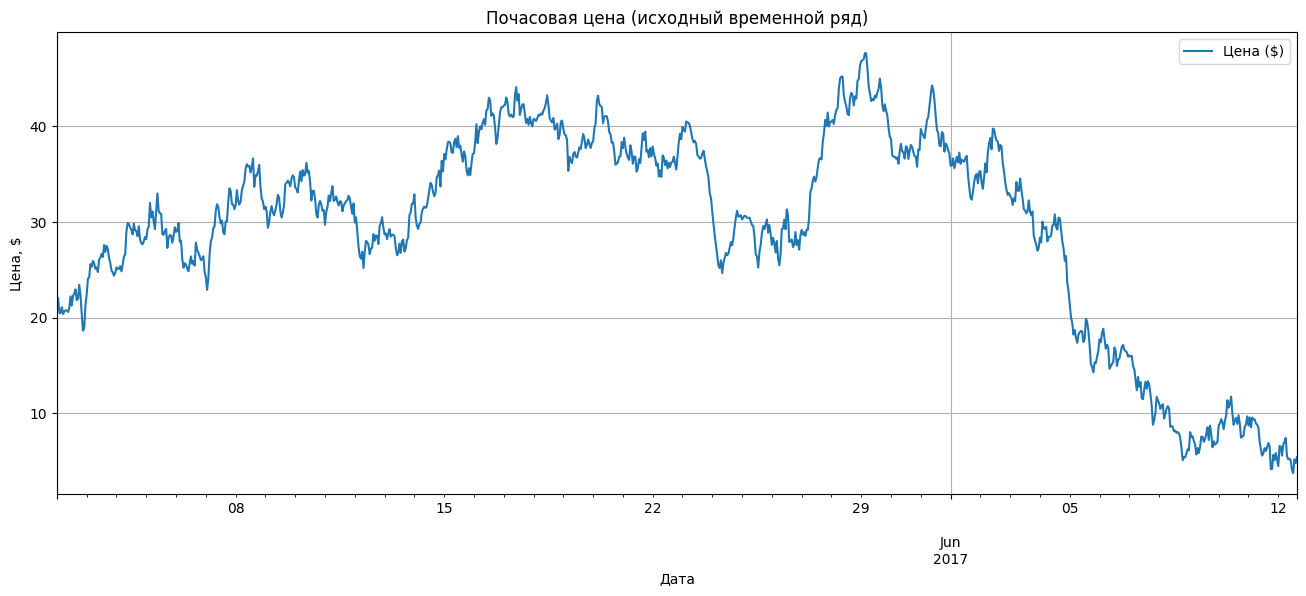

In [6]:
# построим график исходного (почасового) временного ряда цены

data.plot(figsize=(16, 6),
          grid=True,
          xlabel='Дата',
          ylabel='Цена, $',
          title='Почасовая цена (исходный временной ряд)')
plt.legend(['Цена ($)'])
plt.show()

## 2. Группировка данных по дням (среднее значение)

In [7]:
# группируем данные по дням, агрегирующая функция - среднее значение

data_daily = data.resample('D').mean()
data_daily.head()

,Price ($)
Time,
2017-05-02,21.245417
2017-05-03,25.574167
2017-05-04,27.772500
2017-05-05,29.654167
2017-05-06,26.555000


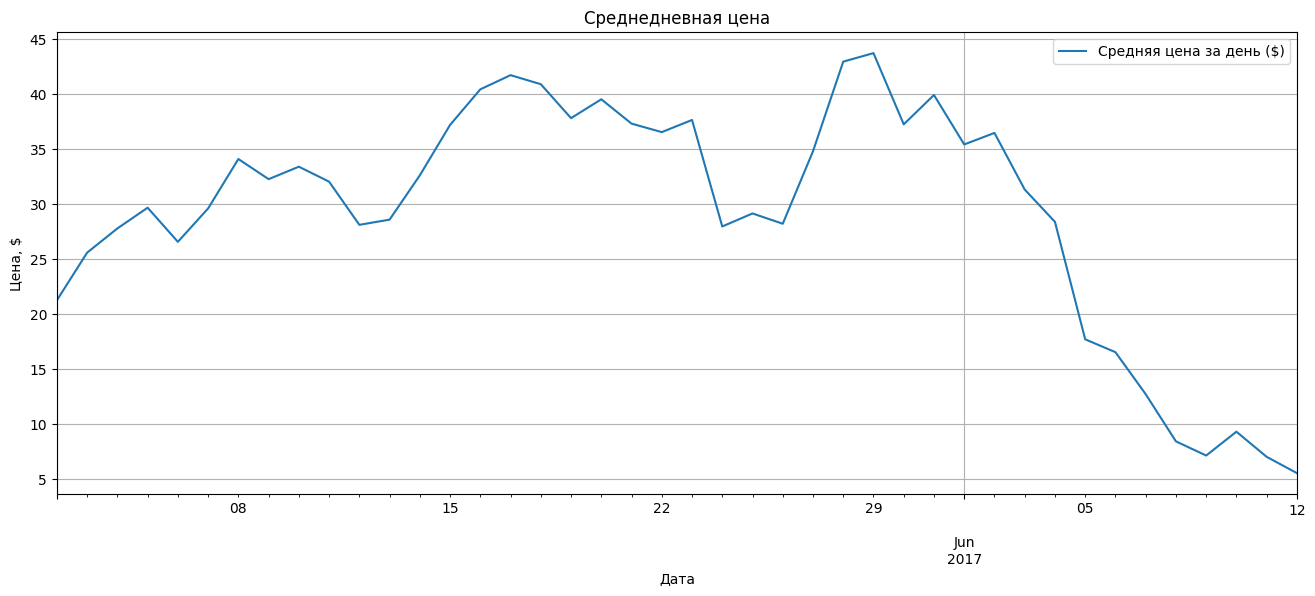

In [8]:
# построим график сгруппированных по дням данных

data_daily.plot(figsize=(16, 6),
                 grid=True,
                 xlabel='Дата',
                 ylabel='Цена, $',
                 title='Среднедневная цена')
plt.legend(['Средняя цена за день ($)'])
plt.show()

## 3. Срез данных за период

Возьмём срез за две недели (с 08.05.2017 по 21.05.2017) из исходного почасового ряда — на таком отрезке удобно рассмотреть возможную суточную сезонность.

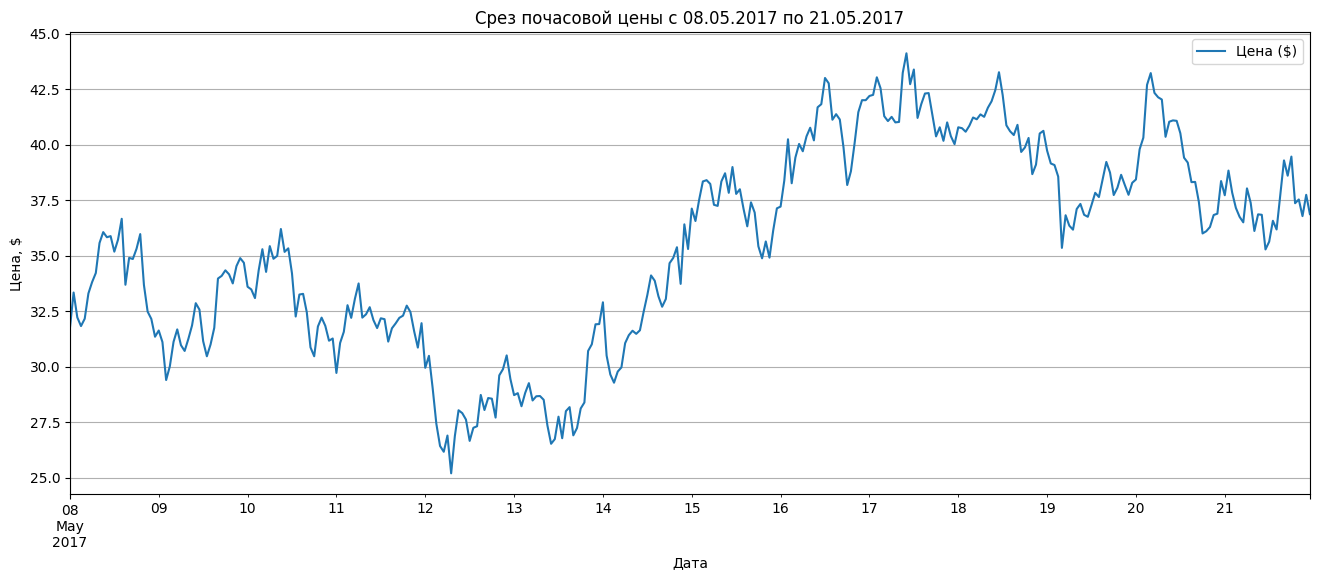

In [9]:
# формируем срез данных за две недели

data_slice = data['2017-05-08':'2017-05-21']

data_slice.plot(figsize=(16, 6),
                 grid=True,
                 xlabel='Дата',
                 ylabel='Цена, $',
                 title='Срез почасовой цены c 08.05.2017 по 21.05.2017')
plt.legend(['Цена ($)'])
plt.show()

## 4. Определение компонент ряда (тренд и сезонность)

Разложим срез почасовых данных на тренд, сезонную составляющую и остаток. Так как данные почасовые, зададим период `period=24` — проверяем наличие суточной сезонности (повторяющегося рисунка в течение 24 часов).

In [10]:
# разложим срез ряда на компоненты (период = 24 часа = 1 сутки)

decomposition = seasonal_decompose(data_slice['Price ($)'],
                                    period=24,
                                    extrapolate_trend='freq')

trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

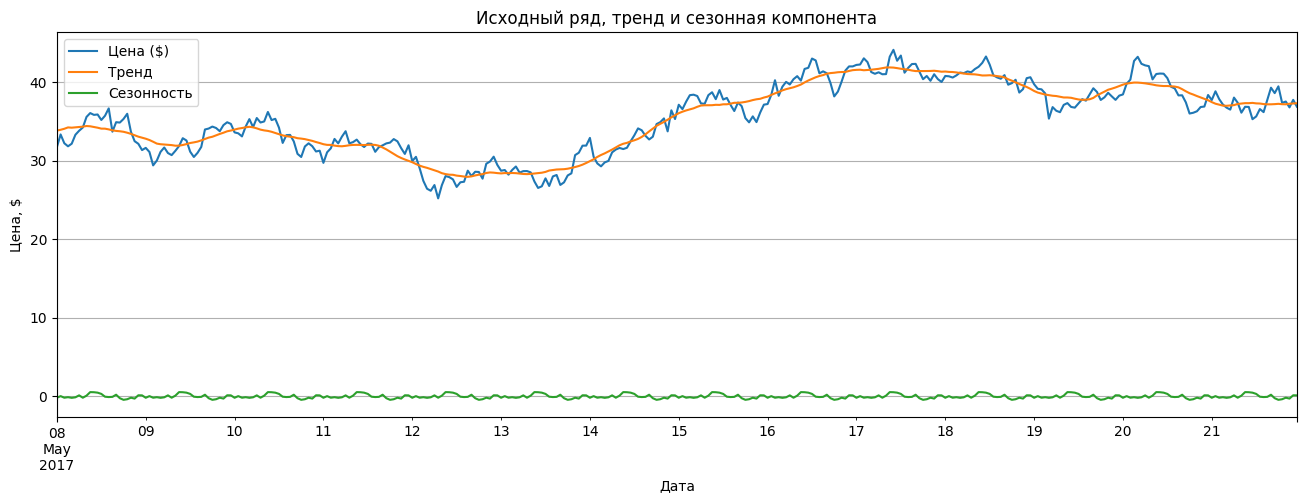

In [11]:
# график исходного ряда, тренда и сезонной компоненты

plt.figure(figsize=(16, 5))
data_slice['Price ($)'].plot()
trend.plot()
seasonal.plot()
plt.grid(True)
plt.xlabel('Дата')
plt.ylabel('Цена, $')
plt.title('Исходный ряд, тренд и сезонная компонента')
plt.legend(['Цена ($)', 'Тренд', 'Сезонность'])
plt.show()

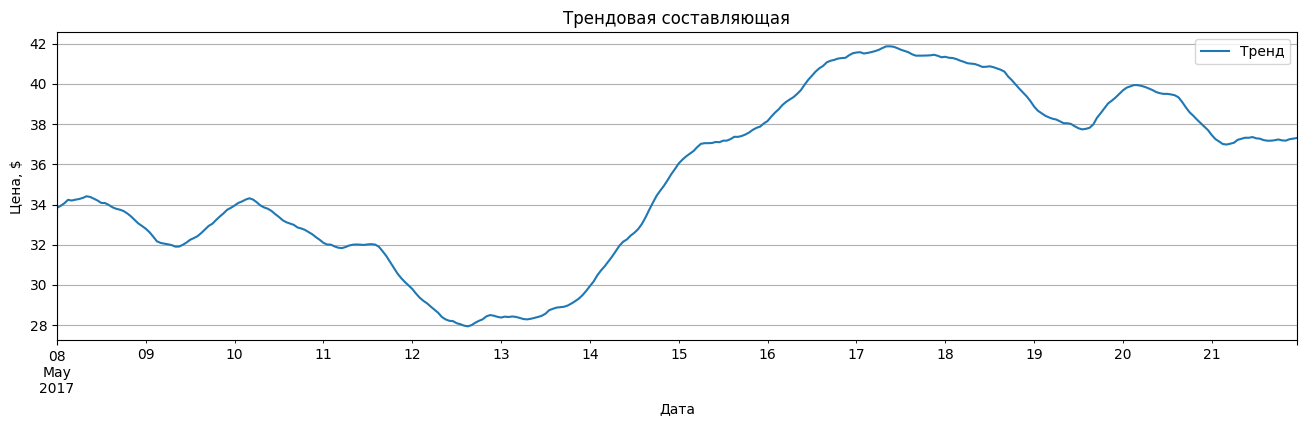

In [12]:
# отдельно график тренда

trend.plot(figsize=(16, 4), grid=True, xlabel='Дата', ylabel='Цена, $',
           title='Трендовая составляющая')
plt.legend(['Тренд'])
plt.show()

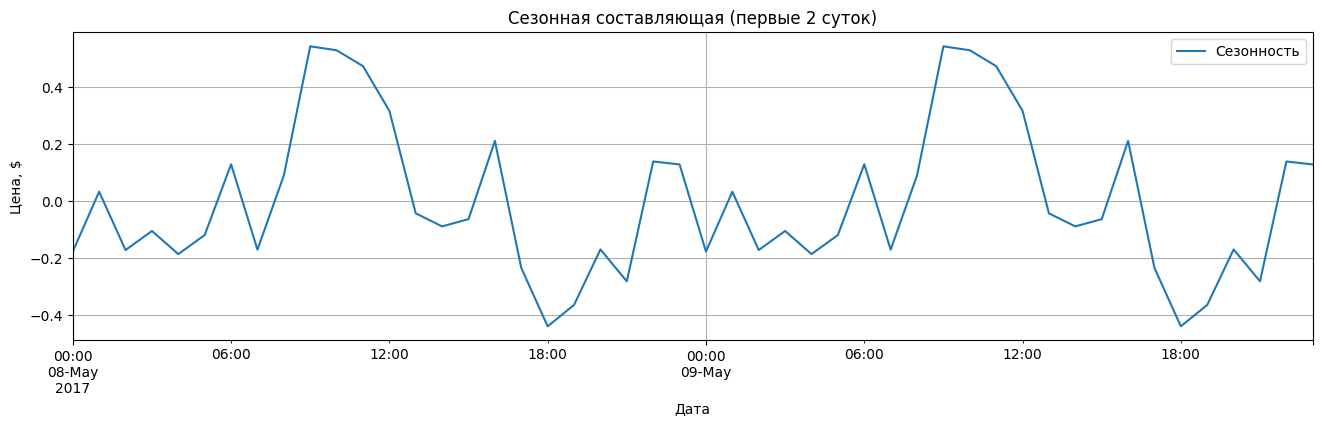

In [13]:
# отдельно график сезонной компоненты (первые 2 суток - один цикл)

seasonal.iloc[:48].plot(figsize=(16, 4), grid=True, xlabel='Дата', ylabel='Цена, $',
                         title='Сезонная составляющая (первые 2 суток)')
plt.legend(['Сезонность'])
plt.show()

## 5. Скользящее среднее

Вычислим скользящее среднее исходного почасового ряда с окном 24 часа (сглаживание за сутки).

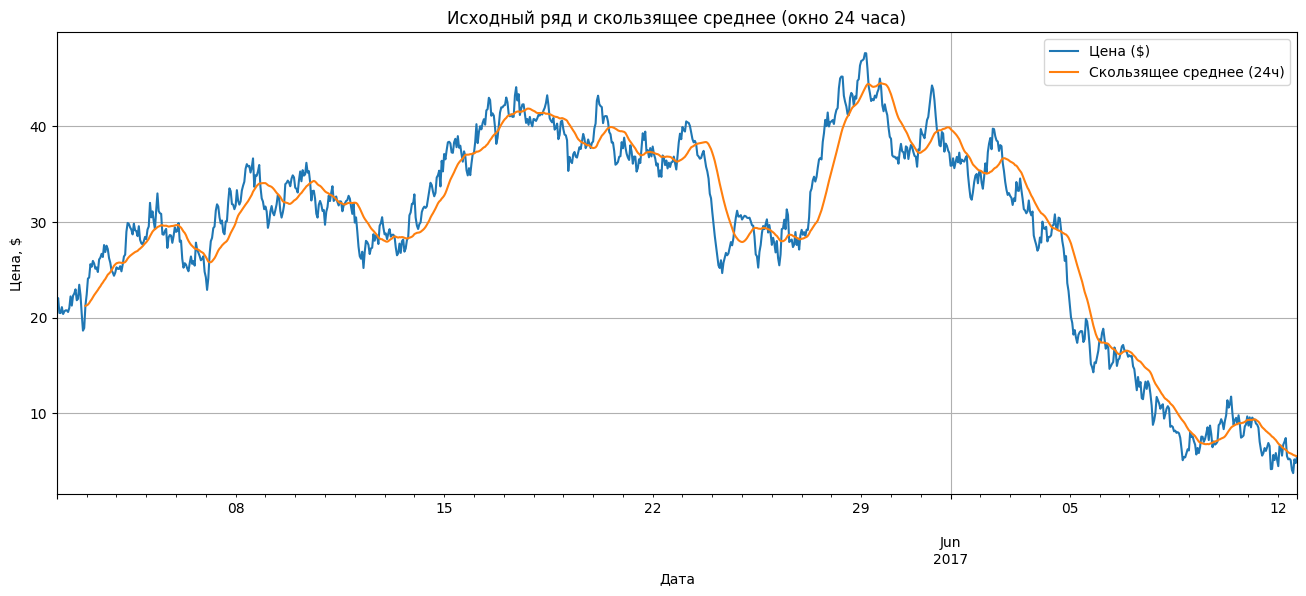

In [ ]:
# вычисляем скользящее среднее ряда (окно = 24 часа)

data_copy = data.copy()
data_copy['rolling_mean_24h'] = data_copy['Price ($)'].rolling(24).mean()

data_copy.plot(figsize=(16, 6),
               grid=True,
               xlabel='Дата',
               ylabel='Цена, $',
               title='Исходный ряд и скользящее среднее (окно 24 часа)')
plt.legend(['Цена ($)', 'Скользящее среднее (24ч)'])
plt.show()

## 6. Визуальный анализ и выводы

- Исходные данные содержат 1000 почасовых наблюдений цены за период с 02.05.2017 00:00 по 12.06.2017 15:00; шаг ряда — 1 час, пропусков в данных не обнаружено.
- Цена изменяется в диапазоне от 3.75$ до 47.67$, среднее значение — 29.48$, стандартное отклонение — 10.49$ — на исходном почасовом графике заметен высокий уровень шума (случайной составляющей), характерный для рыночных данных.
- После группировки по дням случайные колебания частично сглаживаются, и на графике среднедневной цены становится заметна более плавная динамика: чередование периодов роста и снижения цены (просматривается слабо выраженная циклическая составляющая на масштабе нескольких дней).
- На срезе за две недели (08.05–21.05.2017) видно, что внутри суток цена колеблется вокруг локального уровня без явно выраженного устойчивого суточного паттерна: диапазон значений сезонной компоненты (при period=24) невелик по сравнению с общей амплитудой ряда, то есть выраженной суточной сезонности в данных не обнаружено — колебания больше похожи на случайный шум.
- Трендовая составляющая на выбранном срезе демонстрирует плавный локальный рост цены в середине периода, что говорит о наличии кратковременного (локального) тренда, а не о глобальной устойчивой тенденции на всём диапазоне данных.
- Скользящее среднее с окном 24 часа хорошо сглаживает часовой шум и позволяет увидеть общую динамику цены: несколько локальных подъёмов и спадов, что говорит о нестационарном характере среднего значения ряда на отдельных участках.
- Итоговый вывод: временной ряд цены - нестационарный, с высокой случайной составляющей (шумом), без выраженной суточной сезонности и с локальными (краткосрочными) трендовыми участками, а не единым глобальным трендом. Для прогнозирования подобного ряда целесообразно использовать модели, устойчивые к шуму и не требующие строгой стационарности (например, регрессионные модели машинного обучения или нейросетевые модели LSTM/GRU), либо предварительно провести сглаживание (скользящее среднее) и, при необходимости, привести ряд к стационарному виду (например, дифференцированием) перед применением моделей типа ARIMA.
